In [1]:
import os
import sys
import platform
import subprocess
from pathlib import Path

# Check system information
print("SYSTEM INFORMATION")
print("------------------")

print("Operating system:", platform.system())
print("Processor:", platform.processor())
print("Architecture:", platform.machine())
print("Python version:", sys.version)

# Check RAM (Mac)
ram_bytes = int(
    subprocess.check_output(
        ["sysctl", "-n", "hw.memsize"]
    ).decode().strip()
)

ram_gb = ram_bytes / (1024 ** 3)

print(f"Total RAM: {ram_gb:.1f} GB")

# Create project directory
PROJECT_DIR = Path.home() / "SCENIC_Systems_Biology"

folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "scripts",
    "resources",
    "results/figures",
    "results/regulons",
    "results/networks"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("\nPROJECT DIRECTORY CREATED")
print(PROJECT_DIR)

print("\nAll folders created successfully!")

SYSTEM INFORMATION
------------------
Operating system: Darwin
Processor: arm
Architecture: arm64
Python version: 3.9.6 (default, Mar 12 2025, 20:22:46) 
[Clang 17.0.0 (clang-1700.0.13.3)]
Total RAM: 8.0 GB

PROJECT DIRECTORY CREATED
/Users/gharshithavasanthi/SCENIC_Systems_Biology

All folders created successfully!


In [1]:
import sys
import platform

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Architecture:", platform.machine())

import pyscenic

print("pySCENIC version:", pyscenic.__version__)

Python executable: /Users/gharshithavasanthi/miniconda3/envs/scenic/bin/python
Python version: 3.10.22 | packaged by conda-forge | (main, Oct  6 2026, 22:55:54) [Clang 19.1.7 ]
Architecture: arm64
pySCENIC version: 0.12.1


In [3]:
from pathlib import Path
import urllib.request

PROJECT_DIR = Path.home() / "SCENIC_Systems_Biology"
RAW_DIR = PROJECT_DIR / "data" / "raw"

RAW_DIR.mkdir(parents=True, exist_ok=True)

url = (
    "https://s3-us-west-2.amazonaws.com/"
    "10x.files/samples/cell/pbmc3k/"
    "pbmc3k_filtered_gene_bc_matrices.tar.gz"
)

archive_path = RAW_DIR / "pbmc3k_filtered_gene_bc_matrices.tar.gz"

# Remove an incomplete previous download, if present
if archive_path.exists():
    archive_path.unlink()

print("Downloading PBMC 3k from AWS...")

request = urllib.request.Request(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urllib.request.urlopen(request, timeout=120) as response:
    with open(archive_path, "wb") as output:
        while True:
            chunk = response.read(1024 * 1024)
            if not chunk:
                break
            output.write(chunk)

print("Download successful!")
print("File size:", round(archive_path.stat().st_size / (1024**2), 2), "MB")

Download successful!
File size: 7.27 MB


In [4]:
import tarfile

with tarfile.open(archive_path, "r:gz") as tar:
    tar.extractall(path=RAW_DIR)

print("Extraction successful!")

Extraction successful!


In [5]:
DATA_DIR = RAW_DIR / "filtered_gene_bc_matrices" / "hg19"

print("Dataset files:")

for file in DATA_DIR.iterdir():
    print(file.name)

Dataset files:
genes.tsv
barcodes.tsv
matrix.mtx


In [6]:
from pathlib import Path

PROJECT_DIR = Path.home() / "SCENIC_Systems_Biology"
DATA_DIR = PROJECT_DIR / "data" / "raw" / "filtered_gene_bc_matrices" / "hg19"

for filename in ["genes.tsv", "barcodes.tsv", "matrix.mtx"]:
    file_path = DATA_DIR / filename
    print(filename, "—", "Found" if file_path.exists() else "Missing")

genes.tsv — Found
barcodes.tsv — Found
matrix.mtx — Found


In [7]:
import pandas as pd
from scipy.io import mmread

genes = pd.read_csv(DATA_DIR / "genes.tsv", sep="\t", header=None)
barcodes = pd.read_csv(DATA_DIR / "barcodes.tsv", sep="\t", header=None)

expression_matrix = mmread(DATA_DIR / "matrix.mtx").tocsr()

print("Expression matrix shape:", expression_matrix.shape)
print("Number of genes:", len(genes))
print("Number of cells:", len(barcodes))

Expression matrix shape: (32738, 2700)
Number of genes: 32738
Number of cells: 2700


In [8]:
print("First 10 gene entries:")
display(genes.head(10))

print("Gene file columns:", genes.shape[1])
print("Missing gene names:", genes.isnull().sum().tolist())
print("Duplicate gene symbols:", genes.iloc[:, 1].duplicated().sum())

First 10 gene entries:


,0,1
0,ENSG00000243485,MIR1302-10
1,ENSG00000237613,FAM138A
2,ENSG00000186092,OR4F5
3,ENSG00000238009,RP11-34P13.7
4,ENSG00000239945,RP11-34P13.8
5,ENSG00000237683,AL627309.1
6,ENSG00000239906,RP11-34P13.14
7,ENSG00000241599,RP11-34P13.9
8,ENSG00000228463,AP006222.2
9,ENSG00000237094,RP4-669L17.10


Gene file columns: 2
Missing gene names: [0, 0]
Duplicate gene symbols: 95


In [9]:
import numpy as np

total_counts_per_cell = np.asarray(expression_matrix.sum(axis=0)).flatten()
detected_genes_per_cell = np.asarray(
    (expression_matrix > 0).sum(axis=0)
).flatten()

print("Total counts per cell:")
print(pd.Series(total_counts_per_cell).describe())

print("\nDetected genes per cell:")
print(pd.Series(detected_genes_per_cell).describe())

Total counts per cell:
count     2700.000000
mean      2366.900370
std       1094.262076
min        548.000000
25%       1757.750000
50%       2197.000000
75%       2763.000000
max      15844.000000
dtype: float64

Detected genes per cell:
count    2700.000000
mean      846.994074
std       282.104964
min       212.000000
25%       690.000000
50%       817.000000
75%       953.250000
max      3422.000000
dtype: float64


In [11]:
pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 1.4 MB/s  0:00:06m0:00:0100:010m
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 1.1 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [matplotlib]5 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

gene_names = genes.iloc[:, 1].astype(str)

# Identify mitochondrial genes
mt_mask = gene_names.str.upper().str.startswith("MT-")

print("Total mitochondrial genes:", mt_mask.sum())

# Calculate mitochondrial counts per cell
total_counts = np.asarray(expression_matrix.sum(axis=0)).flatten()

mt_counts = np.asarray(
    expression_matrix[mt_mask.values, :].sum(axis=0)
).flatten()

percent_mt = (mt_counts / np.maximum(total_counts, 1)) * 100

qc = pd.DataFrame({
    "total_counts": total_counts,
    "detected_genes": detected_genes_per_cell,
    "percent_mt": percent_mt
})

display(qc.describe())

Total mitochondrial genes: 13


,total_counts,detected_genes,percent_mt
count,2700.000000,2700.000000,2700.000000
mean,2366.900370,846.994074,2.215132
std,1094.262076,282.104964,1.165438
min,548.000000,212.000000,0.000000
25%,1757.750000,690.000000,1.536238
50%,2197.000000,817.000000,2.029639
75%,2763.000000,953.250000,2.640218
max,15844.000000,3422.000000,22.569028


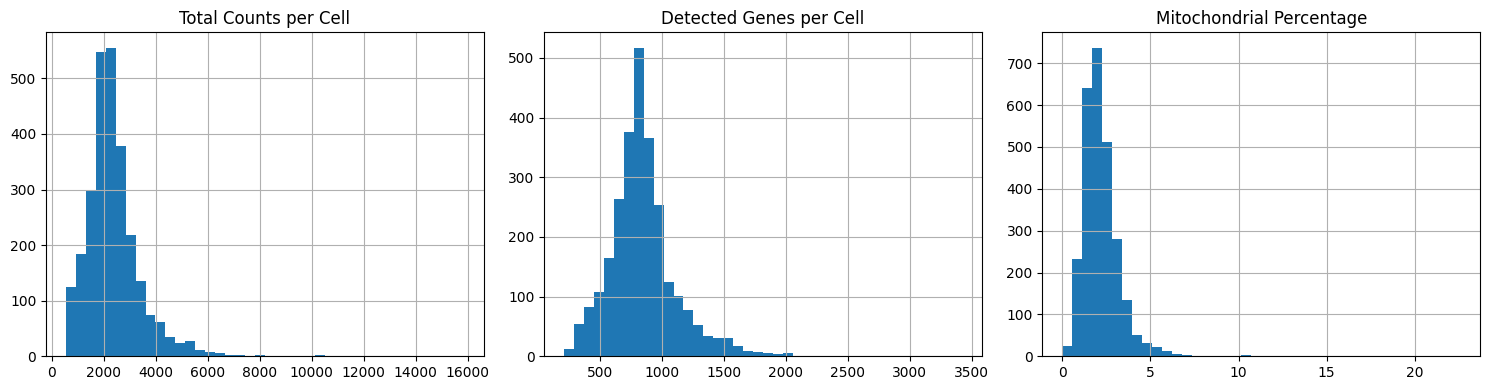

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

qc["total_counts"].hist(bins=40, ax=axes[0])
axes[0].set_title("Total Counts per Cell")

qc["detected_genes"].hist(bins=40, ax=axes[1])
axes[1].set_title("Detected Genes per Cell")

qc["percent_mt"].hist(bins=40, ax=axes[2])
axes[2].set_title("Mitochondrial Percentage")

plt.tight_layout()
plt.show()

In [14]:
import numpy as np
import pandas as pd
from scipy import sparse

# 1. Filter cells
keep_cells = (
    (qc["detected_genes"] >= 200) &
    (qc["detected_genes"] <= 2500) &
    (qc["percent_mt"] <= 10)
).to_numpy()

filtered_matrix = expression_matrix[:, keep_cells]

# 2. Filter genes detected in at least 3 cells
gene_detection = np.asarray(
    (filtered_matrix > 0).sum(axis=1)
).ravel()

keep_genes = gene_detection >= 3

filtered_matrix = filtered_matrix[keep_genes, :]

# 3. Get gene symbols
gene_symbols = genes.iloc[:, 1].astype(str).to_numpy()
gene_symbols = gene_symbols[keep_genes]

# Remove duplicate gene symbols
unique_mask = ~pd.Index(gene_symbols).duplicated()

filtered_matrix = filtered_matrix[unique_mask, :]
gene_symbols = gene_symbols[unique_mask]

# 4. Save as sparse matrix (genes x cells)
from pathlib import Path

processed_dir = PROJECT_DIR / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

sparse.save_npz(
    processed_dir / "pbmc3k_filtered.npz",
    filtered_matrix
)

pd.Series(gene_symbols).to_csv(
    processed_dir / "gene_symbols.csv",
    index=False,
    header=False
)

pd.Series(
    barcodes.iloc[:, 0].to_numpy()[keep_cells]
).to_csv(
    processed_dir / "cell_barcodes.csv",
    index=False,
    header=False
)

print("Filtering complete!")
print("Genes retained:", filtered_matrix.shape[0])
print("Cells retained:", filtered_matrix.shape[1])
print("Files saved to:", processed_dir)

Filtering complete!
Genes retained: 13665
Cells retained: 2689
Files saved to: /Users/gharshithavasanthi/SCENIC_Systems_Biology/data/processed


In [15]:
# Prepare expression matrix: cells x genes

cell_names = barcodes.iloc[:, 0].to_numpy()[keep_cells]

expression_df = pd.DataFrame(
    filtered_matrix.T.toarray(),
    index=cell_names,
    columns=gene_symbols
)

expression_file = processed_dir / "pbmc3k_expression.tsv"

expression_df.to_csv(expression_file, sep="\t")

print("Expression file saved:", expression_file)
print("Expression matrix shape:", expression_df.shape)

Expression file saved: /Users/gharshithavasanthi/SCENIC_Systems_Biology/data/processed/pbmc3k_expression.tsv
Expression matrix shape: (2689, 13665)


In [16]:
import urllib.request

RESOURCE_DIR = PROJECT_DIR / "resources"
RESOURCE_DIR.mkdir(exist_ok=True)

files = {
    "ranking_db.feather":
    "https://resources.aertslab.org/cistarget/databases/homo_sapiens/hg19/refseq_r45/mc9nr/gene_based/hg19-tss-centered-10kb-10species.mc9nr.genes_vs_motifs.rankings.feather",

    "motif_annotations.tbl":
    "https://resources.aertslab.org/cistarget/motif2tf/motifs-v9-nr.hgnc-m0.001-o0.0.tbl",

    "human_TFs.txt":
    "https://resources.aertslab.org/cistarget/tf_lists/allTFs_hg38.txt"
}

for filename, url in files.items():
    destination = RESOURCE_DIR / filename

    if destination.exists() and destination.stat().st_size > 0:
        print(filename, "already downloaded")
        continue

    print("Downloading:", filename)
    urllib.request.urlretrieve(url, destination)
    print("Completed:", filename,
          f"({destination.stat().st_size / (1024**2):.1f} MB)")

Downloading: ranking_db.feather


KeyboardInterrupt: 

In [ ]:
!pyscenic grn --help

In [17]:
ranking_file = RESOURCE_DIR / "ranking_db.feather"

if ranking_file.exists():
    print("Downloaded size:",
          round(ranking_file.stat().st_size / (1024**2), 2), "MB")
else:
    print("File has not been created yet.")

Downloaded size: 865.95 MB


In [18]:
ranking_file = RESOURCE_DIR / "ranking_db.feather"

print("File exists:", ranking_file.exists())

if ranking_file.exists():
    print("Current size:",
          round(ranking_file.stat().st_size / (1024**2), 2), "MB")

File exists: True
Current size: 865.95 MB


In [19]:
import requests

url = files["ranking_db.feather"]
response = requests.head(url, allow_redirects=True, timeout=30)

print("Server status:", response.status_code)
print("Total file size:",
      round(int(response.headers.get("Content-Length", 0)) / (1024**2), 2),
      "MB")
print("Supports resume:",
      response.headers.get("Accept-Ranges", "Not specified"))

Server status: 200
Total file size: 958.35 MB
Supports resume: bytes


In [20]:
import requests

url = files["ranking_db.feather"]
ranking_file = RESOURCE_DIR / "ranking_db.feather"

downloaded = ranking_file.stat().st_size

headers = {
    "Range": f"bytes={downloaded}-",
    "User-Agent": "Mozilla/5.0"
}

with requests.get(
    url,
    headers=headers,
    stream=True,
    timeout=120
) as response:

    print("Response status:", response.status_code)

    if response.status_code != 206:
        raise RuntimeError("Server did not resume the download. Stop here.")

    with open(ranking_file, "ab") as output:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                output.write(chunk)

print("Download completed!")
print("Final size:",
      round(ranking_file.stat().st_size / (1024**2), 2), "MB")

Response status: 206
Download completed!
Final size: 958.35 MB


In [21]:
import urllib.request

remaining_files = {
    "motif_annotations.tbl":
    "https://resources.aertslab.org/cistarget/motif2tf/motifs-v9-nr.hgnc-m0.001-o0.0.tbl",

    "human_TFs.txt":
    "https://resources.aertslab.org/cistarget/tf_lists/allTFs_hg38.txt"
}

for filename, url in remaining_files.items():
    destination = RESOURCE_DIR / filename

    if destination.exists() and destination.stat().st_size > 0:
        print(filename, "already exists")
        continue

    print("Downloading:", filename)
    urllib.request.urlretrieve(url, destination)
    print("Completed:", filename,
          round(destination.stat().st_size / (1024**2), 2), "MB")

Downloading: motif_annotations.tbl
Completed: motif_annotations.tbl 98.77 MB
Downloading: human_TFs.txt
Completed: human_TFs.txt 0.01 MB


In [22]:
for filename in [
    "ranking_db.feather",
    "motif_annotations.tbl",
    "human_TFs.txt"
]:
    path = RESOURCE_DIR / filename
    print(filename, "—", path.stat().st_size if path.exists() else "MISSING")

ranking_db.feather — 1004905162
motif_annotations.tbl — 103568514
human_TFs.txt — 11690


In [23]:
import pandas as pd

# Check TF list
tf_file = RESOURCE_DIR / "human_TFs.txt"

with open(tf_file) as f:
    tf_lines = [line.strip() for line in f if line.strip()]

print("Number of TF entries:", len(tf_lines))
print("First 10 TF entries:", tf_lines[:10])

# Check motif annotation file
motif_file = RESOURCE_DIR / "motif_annotations.tbl"

motif_annotations = pd.read_csv(
    motif_file, sep="\t", nrows=5
)

print("\nMotif annotation columns:")
print(motif_annotations.columns.tolist())
display(motif_annotations.head())

Number of TF entries: 1892
First 10 TF entries: ['ZNF354C', 'KLF12', 'ZNF143', 'ZIC2', 'ZNF274', 'SP2', 'ZBTB7A', 'BCL6B', 'ZBTB49', 'ZIC1']

Motif annotation columns:
['#motif_id', 'motif_name', 'motif_description', 'source_name', 'source_version', 'gene_name', 'motif_similarity_qvalue', 'similar_motif_id', 'similar_motif_description', 'orthologous_identity', 'orthologous_gene_name', 'orthologous_species', 'description']


,#motif_id,motif_name,motif_description,source_name,source_version,gene_name,motif_similarity_qvalue,similar_motif_id,similar_motif_description,orthologous_identity,orthologous_gene_name,orthologous_species,description
0,bergman__Abd-B,Abd-B,Abd-B,bergman,1.1,HOXA9,0.0006,cisbp__M1008,"HOXA6[gene ID: ""ENSG00000106006"" species: ""Hom...",0.981618,ENSMUSG00000038227,M. musculus,gene is orthologous to ENSMUSG00000038227 in M...
1,bergman__Aef1,Aef1,Aef1,bergman,1.1,ZNF8,0.0000,NaN,NaN,0.213656,FBgn0005694,D. melanogaster,motif is annotated for orthologous gene FBgn00...
2,bergman__Cf2,Cf2,Cf2,bergman,1.1,ZNF853,0.0000,NaN,NaN,0.150980,FBgn0000286,D. melanogaster,motif is annotated for orthologous gene FBgn00...
3,bergman__EcR_usp,EcR_usp,EcR/usp,bergman,1.1,NR1H2,0.0000,NaN,NaN,0.378261,FBgn0000546,D. melanogaster,gene is orthologous to FBgn0000546 in D. melan...
4,bergman__EcR_usp,EcR_usp,EcR/usp,bergman,1.1,NR1H3,0.0000,NaN,NaN,0.406181,FBgn0000546,D. melanogaster,gene is orthologous to FBgn0000546 in D. melan...


In [24]:
!pyscenic grn --help

zsh:1: command not found: pyscenic


In [25]:
import sys
import shutil
import os

print("Python executable:", sys.executable)
print("Environment:", sys.prefix)
print("pySCENIC command:", shutil.which("pyscenic"))
print("Python version:", sys.version)

Python executable: /Users/gharshithavasanthi/miniconda3/envs/scenic/bin/python
Environment: /Users/gharshithavasanthi/miniconda3/envs/scenic
pySCENIC command: None
Python version: 3.10.22 | packaged by conda-forge | (main, Oct  6 2026, 22:55:54) [Clang 19.1.7 ]


In [26]:
from pathlib import Path

pyscenic_exe = Path(sys.prefix) / "bin" / "pyscenic"

print("Executable exists:", pyscenic_exe.exists())
print("Executable path:", pyscenic_exe)

Executable exists: True
Executable path: /Users/gharshithavasanthi/miniconda3/envs/scenic/bin/pyscenic


In [27]:
import subprocess

result = subprocess.run(
    [str(pyscenic_exe), "grn", "--help"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

usage: pyscenic grn [-h] [-o OUTPUT] [-t] [-m {genie3,grnboost2}]
                    [--seed SEED] [--num_workers NUM_WORKERS]
                    [--client_or_address CLIENT_OR_ADDRESS]
                    [--cell_id_attribute CELL_ID_ATTRIBUTE]
                    [--gene_attribute GENE_ATTRIBUTE] [--sparse]
                    expression_mtx_fname tfs_fname

positional arguments:
  expression_mtx_fname  The name of the file that contains the expression
                        matrix for the single cell experiment. Two file
                        formats are supported: csv (rows=cells x
                        columns=genes) or loom (rows=genes x columns=cells).
  tfs_fname             The name of the file that contains the list of
                        transcription factors (TXT; one TF per line).

options:
  -h, --help            show this help message and exit
  -o OUTPUT, --output OUTPUT
                        Output file/stream, i.e. a table of TF-target genes
             

In [28]:
# Convert expression matrix to CSV
expression_csv = processed_dir / "pbmc3k_expression.csv"

expression_df.to_csv(expression_csv)

# Keep only TFs present in our filtered expression matrix
available_genes = set(gene_symbols)

filtered_tfs = [
    tf for tf in tf_lines
    if tf in available_genes
]

tf_file = RESOURCE_DIR / "human_TFs_filtered.txt"

with open(tf_file, "w") as f:
    f.write("\n".join(filtered_tfs))

print("Expression CSV:", expression_csv)
print("Expression shape:", expression_df.shape)
print("TFs available:", len(filtered_tfs))
print("TF list saved:", tf_file)

Expression CSV: /Users/gharshithavasanthi/SCENIC_Systems_Biology/data/processed/pbmc3k_expression.csv
Expression shape: (2689, 13665)
TFs available: 1270
TF list saved: /Users/gharshithavasanthi/SCENIC_Systems_Biology/resources/human_TFs_filtered.txt


In [29]:
import subprocess

adjacency_file = PROJECT_DIR / "results" / "networks" / "adjacencies.csv"

command = [
    str(pyscenic_exe),
    "grn",
    str(expression_csv),
    str(tf_file),
    "--method", "grnboost2",
    "--num_workers", "1",
    "--seed", "42",
    "--output", str(adjacency_file)
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-4000:])
print(result.stderr[-4000:])

Return code: 0
preparing dask client
parsing input
creating dask graph
1 partitions
computing dask graph
not shutting down client, client was created externally
finished

/Users/gharshithavasanthi/miniconda3/envs/scenic/lib/python3.10/site-packages/ctxcore/__init__.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution

2026-11-10 08:53:07,210 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2026-11-10 08:53:09,586 - pyscenic.cli.pyscenic - INFO - Inferring regulatory networks.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
/Users/gharshitha

In [30]:
adjacencies = pd.read_csv(adjacency_file)

print("Total regulatory interactions:", len(adjacencies))
print("\nColumns:")
print(adjacencies.columns.tolist())

display(adjacencies.head(10))

Total regulatory interactions: 1033945

Columns:
['TF', 'target', 'importance']


,TF,target,importance
0,SP110,DENND1B,14.565025
1,ZNF574,MPHOSPH6,13.887835
2,CANX,OSTC,11.988640
3,USF2,RFT1,11.712218
4,RPS4X,RPS3,11.701861
5,UGP2,PPP1R12C,11.677464
6,HMG20A,APC,11.502010
7,MTF1,IRAK1,11.360779
8,RPS4X,RPL17,11.253397
9,MSRA,JKAMP,11.129699


In [31]:
print("Unique transcription factors:",
      adjacencies["TF"].nunique())

print("Unique target genes:",
      adjacencies["target"].nunique())

print("Top 10 regulatory interactions:")

display(
    adjacencies.sort_values(
        "importance", ascending=False
    ).head(10)
)

Unique transcription factors: 1270
Unique target genes: 13665
Top 10 regulatory interactions:


,TF,target,importance
0,SP110,DENND1B,14.565025
1,ZNF574,MPHOSPH6,13.887835
2,CANX,OSTC,11.988640
3,USF2,RFT1,11.712218
4,RPS4X,RPS3,11.701861
5,UGP2,PPP1R12C,11.677464
6,HMG20A,APC,11.502010
7,MTF1,IRAK1,11.360779
8,RPS4X,RPL17,11.253397
9,MSRA,JKAMP,11.129699


In [32]:
print("Unexpected candidates in TF list:")

for gene in ["CANX", "UGP2", "MSRA", "SP110", "USF2"]:
    print(gene, gene in tf_lines)

Unexpected candidates in TF list:
CANX True
UGP2 True
MSRA True
SP110 True
USF2 True


In [33]:
result = subprocess.run(
    [str(pyscenic_exe), "ctx", "--help"],
    capture_output=True,
    text=True
)

print(result.stdout)

usage: pyscenic ctx [-h] [-o OUTPUT] [-n] [--chunk_size CHUNK_SIZE]
                    [--mode {custom_multiprocessing,dask_multiprocessing,dask_cluster}]
                    [-a] [-t] [--rank_threshold RANK_THRESHOLD]
                    [--auc_threshold AUC_THRESHOLD]
                    [--nes_threshold NES_THRESHOLD]
                    [--min_orthologous_identity MIN_ORTHOLOGOUS_IDENTITY]
                    [--max_similarity_fdr MAX_SIMILARITY_FDR]
                    --annotations_fname ANNOTATIONS_FNAME
                    [--num_workers NUM_WORKERS]
                    [--client_or_address CLIENT_OR_ADDRESS]
                    [--thresholds THRESHOLDS [THRESHOLDS ...]]
                    [--top_n_targets TOP_N_TARGETS [TOP_N_TARGETS ...]]
                    [--top_n_regulators TOP_N_REGULATORS [TOP_N_REGULATORS ...]]
                    [--min_genes MIN_GENES]
                    [--expression_mtx_fname EXPRESSION_MTX_FNAME]
                    [--mask_dropouts] [--cell_id

In [35]:
old_file = RESOURCE_DIR / "ranking_db.feather"

new_file = RESOURCE_DIR / (
    "hg19-tss-centered-10kb-10species."
    "mc9nr.genes_vs_motifs.rankings.feather"
)

if old_file.exists():
    old_file.rename(new_file)

print("Database renamed:", new_file.exists())
print("New filename:", new_file.name)

Database renamed: True
New filename: hg19-tss-centered-10kb-10species.mc9nr.genes_vs_motifs.rankings.feather


In [36]:
regulons_file = PROJECT_DIR / "results" / "regulons" / "regulons.csv"

command = [
    str(pyscenic_exe),
    "ctx",
    str(adjacency_file),
    str(new_file),
    "--annotations_fname",
    str(RESOURCE_DIR / "motif_annotations.tbl"),
    "--expression_mtx_fname",
    str(expression_csv),
    "--mode",
    "custom_multiprocessing",
    "--num_workers",
    "1",
    "--nes_threshold",
    "3.0",
    "--output",
    str(regulons_file)
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("OUTPUT:")
print(result.stdout[-3000:])
print("ERRORS:")
print(result.stderr[-3000:])
result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("OUTPUT:")
print(result.stdout[-4000:])
print("ERRORS:")
print(result.stderr[-4000:])

Return code: 0
OUTPUT:

ERRORS:
ngs. Skipping this module.

2026-11-10 10:04:44,817 - pyscenic.transform - WARNING - Less than 80% of the genes in ZNF93 could be mapped to hg19-tss-centered-10kb-10species.mc9nr.genes_vs_motifs.rankings. Skipping this module.

2026-11-10 10:04:45,002 - pyscenic.transform - WARNING - Less than 80% of the genes in ZSCAN16 could be mapped to hg19-tss-centered-10kb-10species.mc9nr.genes_vs_motifs.rankings. Skipping this module.

2026-11-10 10:04:45,056 - pyscenic.transform - WARNING - Less than 80% of the genes in ZSCAN18 could be mapped to hg19-tss-centered-10kb-10species.mc9nr.genes_vs_motifs.rankings. Skipping this module.

2026-11-10 10:04:45,104 - pyscenic.transform - WARNING - Less than 80% of the genes in ZSCAN2 could be mapped to hg19-tss-centered-10kb-10species.mc9nr.genes_vs_motifs.rankings. Skipping this module.

2026-11-10 10:04:45,162 - pyscenic.transform - WARNING - Less than 80% of the genes in ZSCAN21 could be mapped to hg19-tss-centered-10k

KeyboardInterrupt: 

In [37]:
print("Jupyter is responsive!")
print("GRN results:", adjacency_file.exists())

Jupyter is responsive!
GRN results: True


In [38]:
print("GRN results exist:", adjacency_file.exists())
print("GRN file size (MB):",
      round(adjacency_file.stat().st_size / (1024**2), 2))

print("Ranking database exists:", new_file.exists())
print("Motif annotations exist:",
      (RESOURCE_DIR / "motif_annotations.tbl").exists())

GRN results exist: True
GRN file size (MB): 32.62
Ranking database exists: True
Motif annotations exist: True


In [39]:
import shutil

backup_file = PROJECT_DIR / "results" / "networks" / "adjacencies_backup.csv"

shutil.copy2(adjacency_file, backup_file)

print("Backup created:", backup_file.exists())
print("Backup size (MB):",
      round(backup_file.stat().st_size / (1024**2), 2))

Backup created: True
Backup size (MB): 32.62


In [40]:
import requests

small_db_url = (
    "https://resources.aertslab.org/cistarget/databases/"
    "homo_sapiens/hg19/refseq_r45/mc9nr/gene_based/"
    "hg19-500bp-upstream-7species.mc9nr.feather"
)

response = requests.head(
    small_db_url,
    allow_redirects=True,
    timeout=30
)

print("Server status:", response.status_code)

size = response.headers.get("Content-Length")

if size:
    print("Database size (MB):", round(int(size) / (1024**2), 2))
else:
    print("Database size not provided by server")

Server status: 404
Database size not provided by server
